# Numerical simulation for double-bracket quantum algorithms for quantum imaginary-time evolution (DB-QITE) using density matrix exponentiation (DME)

## 1. Initialization

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import expm
import warnings
warnings.filterwarnings("ignore", category=UserWarning)

import sys
sys.path.append('..')
from functions.qite_gci import *
from functions.qite_dme import *
from functions.plot_bloch_sphere import *

# Plot config
plt.rcParams.update({
    'axes.labelsize': 16,
    'axes.titlesize': 16,
    'font.size': 16,
    'savefig.dpi': 75,
    'lines.linewidth': 2.0,
    'lines.markersize': 8,
    'legend.fontsize': 14,
    'legend.labelspacing': .3,
    'legend.columnspacing': .3,
    'legend.handletextpad': .1,
    'text.usetex': True,
    'font.family': "serif",
    'font.serif': "cm",
    'figure.figsize': [5, 3.5],
    'figure.autolayout': True
})

---
## 2. Run DB-QITE with DME

### 2.1 Find optimal s
Import the optimal s array generated in `find_optimal_s_dbqite.ipynb`

In [27]:
optimal_s_Mk = np.load('optimal_s_Mk.npy')

### 2.2 k = 1

This section shows **DB-QITE** results for different initial states, parameterized by recursion steps \(k\) and DME Trotter steps \(M\).

- The **x-axis** shows the fidelity of each initial state with the ground state. These initial states are prepared by applying \( RX(\theta) \) rotations to \(\ket{0}\), varying only the **latitude** on the Bloch sphere. This is because energy—relevant for state reset—depends on **latitude**, not longitude.
- The **y-axis** shows the fidelity with the ground state **after DB-QITE**. Higher values (closer to 1) indicate better reset performance.

#### Parameters

- `Ms = [1, 2, 50]`: List of \(M\) values representing DME memory (Trotter) steps.
- `k = 1`: Number of DB-QITE recursion iterations.

#### 1. Generate Initial States

- `thetas` is a linear space of 100 values from 0 to 1.
- `sigma_x` is the Pauli-X matrix.
- `psis` is a list of quantum states generated by evolving the state \(|1\rangle\) under the Pauli-X Hamiltonian:
  
  \[
  \ket{\psi(\theta)} = e^{-i \frac{\pi}{2} \theta \sigma_x} \ket{1}
  \]

#### 2. Run DB-QITE for Each M

- For each \(M \in \{1, 2, 50\}\), the DB-QITE energy is computed using the optimal step size \(s\) stored in `optimal_s_Mk`.
- Final fidelity is computed as:

  \[
  F = \frac{1 - E}{2}
  \]

  where \(E\) is the final energy returned by the DB-QITE routine (closer to 1 implies worse fidelity, so subtracting and scaling brings it back to fidelity-like form).


In [29]:
Ms = [1, 2, 50]
k = 1

# Initial state sweep
thetas = np.linspace(0, 1, 100)
sigma_x = np.array([[0, 1], [1, 0]])
psis = [expm(-1j * np.pi/2 * sigma_x * t) @ np.array([[0], [1]]) for t in thetas]
psis = np.asarray(psis)

# Baseline GCI energy results
res_init = [GCI(initial_psi, psi, 1, np.linspace(0.01, 1, 2)).execute_gci()[0][-1] for psi in psis]

# Run DB-QITE for each M with optimal s
dict_res_DBQITE = {}
for M in Ms:
    res_DBQITE = [GCI(QITE_dme_select_M(M), psi, None, optimal_s_Mk[M-1][:k]).execute_gci()[0][-1] for psi in psis]
    dict_res_DBQITE[f'M={np.round(M,2)}'] = res_DBQITE

    print(f"M = {M}, k = {k}: s = {np.round(optimal_s_Mk[M-1][:k], 2)}, φ = {np.round(np.sqrt(optimal_s_Mk[M-1][:k]), 2)}")
    print(f"t = {np.round(np.sqrt(optimal_s_Mk[M-1][:k]) / (2 * np.pi * M), 4)} τ")

# Compute fidelities: (1 - E)/2
dict_fid_RGCI = {key: [(1 - E) / 2 for E in values] for key, values in dict_res_DBQITE.items()}

0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of inter

c:\Python\Lib\site-packages\matplotlib\cbook.py:1709: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
c:\Python\Lib\site-packages\matplotlib\cbook.py:1345: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


(1, 0.68)
(2, 0.62)
(50, 0.52)


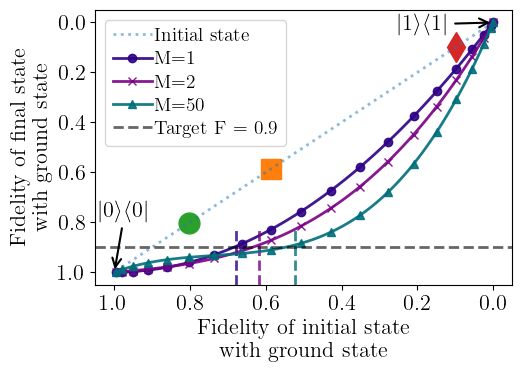

In [30]:
target_fidelity = 0.9

# Define reference state |0⟩⟨0|
state_0 = np.array([1, 0], dtype=complex)

# Fidelity with respect to |0⟩ for both pure and mixed states
def fidelity_with_0(state):
    return np.real(np.conj(state_0).T @ (state @ state.T.conj() if state.ndim == 2 and state.shape[1] == 1 else state) @ state_0)

# Initial state fidelities and RGCI outputs
fidelities_original = [fidelity_with_0(x) for x in psis]
fidelity = [(1 - E) / 2 for E in res_init]

# Plot setup
color = ['#2c0084', '#7a0085', '#006f7a', 'C0']
markers = ['o','x','^','*','P','*','h']
max_ext_list = []
 
fig, ax = plt.subplots(figsize=(5.5, 4))
ax.plot(fidelities_original, fidelity, label="Initial state", alpha=0.5, linestyle=':')

# Highlight three specific points
plt.plot(fidelities_original[70], fidelity[70], 'o', color='C2', markersize=15, zorder=0)
plt.plot(fidelities_original[55], fidelity[55], 's', color='C1', markersize=15, zorder=0)
plt.plot(fidelities_original[20], fidelity[20], 'd', color='C3', markersize=15, zorder=0)

# Plot each RGCI curve and draw vertical line at max excitation fidelity above target
for i, (key, value) in enumerate(dict_fid_RGCI.items()):
    max_ext = max_excitation(fidelities_original, np.real(value), target_fidelity)
    if max_ext: ax.axvline(x=max_ext, ymax=0.2, color=color[i], alpha=0.8, linestyle='--')
    max_ext_list.append(max_ext)
    ax.plot(fidelities_original, value, label=key, color=color[i],
            marker=markers[i], markevery=5, markersize=6, alpha=0.9)

# Reverse axes: higher overlap → left/lower corner
plt.gca().invert_xaxis()
plt.gca().invert_yaxis()
ax.axhline(y=target_fidelity, color='k', alpha=0.6, linestyle='--', label=f'Target F = {target_fidelity}')

# Labels and legend
ax.set_xlabel('Fidelity of initial state\nwith ground state')
ax.set_ylabel('Fidelity of final state\nwith ground state')
ax.legend()

# Annotate |1⟩ and |0⟩ 
ax.annotate(r'$|1\rangle\langle 1|$', xy=(fidelities_original[0], fidelity[0]), 
            xytext=(fidelities_original[0]+0.25, fidelity[0]+0.03), arrowprops=dict(arrowstyle='->', lw=1.5))
ax.annotate(r'$|0\rangle\langle 0|$', xy=(fidelities_original[-1], fidelity[-1]), 
            xytext=(fidelities_original[-1]+0.04, fidelity[-1]-0.22), arrowprops=dict(arrowstyle='->', lw=1.5))

plt.tight_layout()
plt.savefig(f'plots/QITE_DME_k_{k}_M_fidelity_final_vs_original.pdf')

# Report max fidelity locations
for M, max_val in zip(Ms, max_ext_list):
    print((M, np.round(max_val, 2)))

### 2.2 k=2

In [31]:
Ms = [1, 2, 50]
k = 2

# Run DB-QITE for each M with optimal s
dict_res_DBQITE = {}
for M in Ms:
    res_DBQITE = [GCI(QITE_dme_select_M(M), psi, None, optimal_s_Mk[M-1][:k]).execute_gci()[0][-1] for psi in psis]
    dict_res_DBQITE[f'M={np.round(M,2)}'] = res_DBQITE

    print(f"M = {M}, k = {k}: s = {np.round(optimal_s_Mk[M-1][:k], 2)}, φ = {np.round(np.sqrt(optimal_s_Mk[M-1][:k]), 2)}")
    print(f"t = {np.round(np.sqrt(optimal_s_Mk[M-1][:k]) / (2 * np.pi * M), 4)} τ")

# Compute fidelities: (1 - E)/2
dict_fid_RGCI = {key: [(1 - E) / 2 for E in values] for key, values in dict_res_DBQITE.items()}

M = 1, k = 2: s = [0.79 0.79], φ = [0.89 0.89]
t = [0.141 0.141] τ
M = 2, k = 2: s = [0.88 0.8 ], φ = [0.94 0.89]
t = [0.0745 0.071 ] τ
M = 50, k = 2: s = [0.95 0.74], φ = [0.98 0.86]
t = [0.0031 0.0027] τ


(1, 0.54)
(2, 0.51)
(50, 0.24)


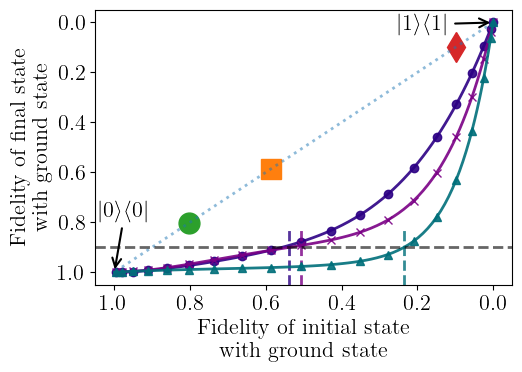

In [32]:
# Define reference state |0⟩⟨0|
state_0 = np.array([1, 0], dtype=complex)

# Fidelity with respect to |0⟩ for both pure and mixed states
def fidelity_with_0(state):
    return np.real(np.conj(state_0).T @ (state @ state.T.conj() if state.ndim == 2 and state.shape[1] == 1 else state) @ state_0)

# Initial state fidelities and RGCI outputs
fidelities_original = [fidelity_with_0(x) for x in psis]
fidelity = [(1 - E) / 2 for E in res_init]

# Plot setup
max_ext_list = []

fig, ax = plt.subplots(figsize=(5.5, 4))
ax.plot(fidelities_original, fidelity, label="Initial state", alpha=0.5, linestyle=':')

# Highlight three specific points
plt.plot(fidelities_original[70], fidelity[70], 'o', color='C2', markersize=15, zorder=0)
plt.plot(fidelities_original[55], fidelity[55], 's', color='C1', markersize=15, zorder=0)
plt.plot(fidelities_original[20], fidelity[20], 'd', color='C3', markersize=15, zorder=0)

# Plot each RGCI curve and draw vertical line at max excitation fidelity above target
for i, (key, value) in enumerate(dict_fid_RGCI.items()):
    max_ext = max_excitation(fidelities_original, np.real(value), target_fidelity)
    if max_ext: ax.axvline(x=max_ext, ymax=0.2, color=color[i], alpha=0.8, linestyle='--')
    max_ext_list.append(max_ext)
    ax.plot(fidelities_original, value, label=key, color=color[i],
            marker=markers[i], markevery=5, markersize=6, alpha=0.9)

# Reverse axes: higher overlap → left/lower corner
plt.gca().invert_xaxis()
plt.gca().invert_yaxis()
ax.axhline(y=target_fidelity, color='k', alpha=0.6, linestyle='--', label=f'Target F = {target_fidelity}')

# Labels and legend
ax.set_xlabel('Fidelity of initial state\nwith ground state')
ax.set_ylabel('Fidelity of final state\nwith ground state')

# Annotate |1⟩ and |0⟩ 
ax.annotate(r'$|1\rangle\langle 1|$', xy=(fidelities_original[0], fidelity[0]), 
            xytext=(fidelities_original[0]+0.25, fidelity[0]+0.03), arrowprops=dict(arrowstyle='->', lw=1.5))
ax.annotate(r'$|0\rangle\langle 0|$', xy=(fidelities_original[-1], fidelity[-1]), 
            xytext=(fidelities_original[-1]+0.04, fidelity[-1]-0.22), arrowprops=dict(arrowstyle='->', lw=1.5))

plt.tight_layout()
plt.savefig(f'plots/QITE_DME_k_{k}_M_fidelity_final_vs_original.pdf')

# Report max fidelity locations
for M, max_val in zip(Ms, max_ext_list):
    print((M, np.round(max_val, 2)))

---
## 3. Plot Bloch sphere for different initialization


Illustration of DB-QITE for different initializations, comparing cases where the initial state is close to or far from the ground state. The dotted black latitude line represents the target fidelity with the ground state, $F_{\text{target}}=0.9$. Each latitude line corresponds to the state indicated by the arrow of the same color, showing both the initial state and its evolution after $k=1$ or $k=2$ steps.
    


### (a) The initial state has a fidelity of $F_{\text{initial}}=80\%$ with the ground state. The target fidelity is achieved after $k=1$ step with $M=1$, requiring only one extra copy of the initial state.

In [33]:
color = ['C0','#2c0084','#7a0085','#006f7a']

In [34]:
states_good = GCI(QITE_dme_select_M(1), psis[70], None, optimal_s_Mk[0][:1]).execute_gci()[-3]
states_mid = GCI(QITE_dme_select_M(1), psis[55], None, optimal_s_Mk[0][:2]).execute_gci()[-3]
states_bad = GCI(QITE_dme_select_M(2), psis[30], None, optimal_s_Mk[1][:2]).execute_gci()[-3]

texts = ['Initial state',r'$k=1$',r'$k=2$']

0.0 0.7957618405308319 (0.605609687137667+0j)
-0.15692037927859365 0.15692038745539902 (0.9222281405601755-5.612726838120619e-18j)


c:\Python\Lib\site-packages\mpl_toolkits\mplot3d\axes3d.py:3305: ComplexWarning: Casting complex values to real discards the imaginary part
  UVW = np.column_stack(input_args[3:]).astype(float)


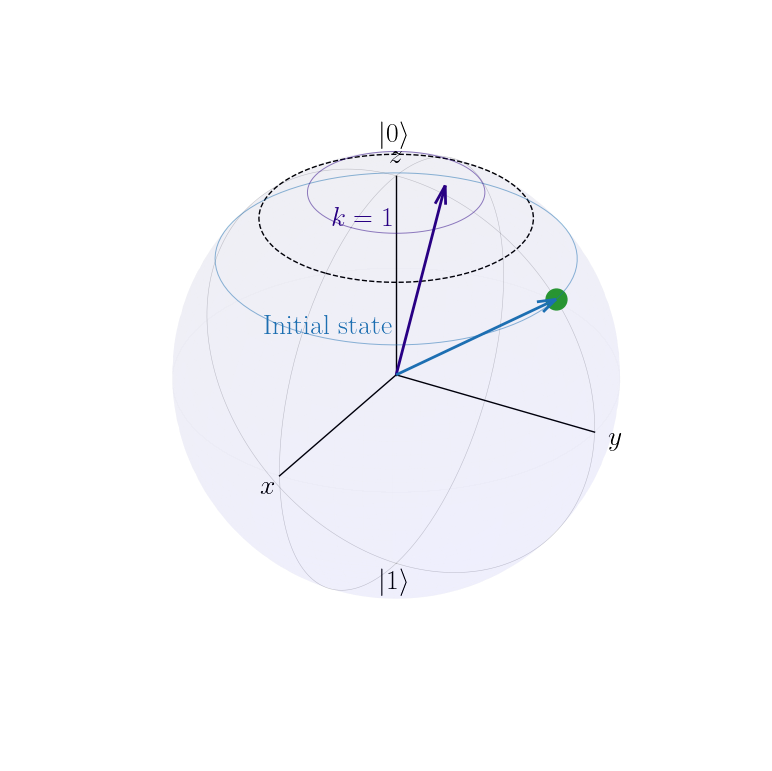

In [35]:
# Create the plot
ax = plot_bloch_sphere()

fidelity = 0.9
theta = 2 * np.arccos(np.sqrt(fidelity))
u = np.linspace(0, 2 * np.pi, 100)
x_latitude = np.outer(np.cos(u), np.sin(theta))
y_latitude = np.outer(np.sin(u), np.sin(theta))
z_latitude = np.outer(np.ones(np.size(u)), np.cos(theta))
ax.plot(x_latitude, y_latitude, z_latitude, color='k', lw=1, alpha=1,linestyle='--')

# Plot the Bloch sphere with vector
i=0
for state in states_good:
    if i==0:
        ax = plot_bloch_vector(state,ax,color=color[i],text=texts[i],marker='o',marker_color='C2')
    else:
        ax = plot_bloch_vector(state,ax,color=color[i],text=texts[i])
    i+=1
# Show the plot
plt.savefig(f'plots/bloch_good.pdf', bbox_inches="tight", pad_inches=-1.1)
plt.show()

### (b) The initial fidelity with the ground state is $F_{\text{initial}} = 60\%$. The target fidelity is reached after $k=2$ steps with $M=2$, which consumes eight extra copies of the initial state.

0.0 0.9848077530122081 (0.1736481776669303+0j)
-0.40689883718230235 0.4068988491272234 (0.6585713328634074-9.677436786386842e-18j)
-0.1389269521990117 3.383275229418284e-08 (0.8241380014240911-4.321543979543875e-18j)


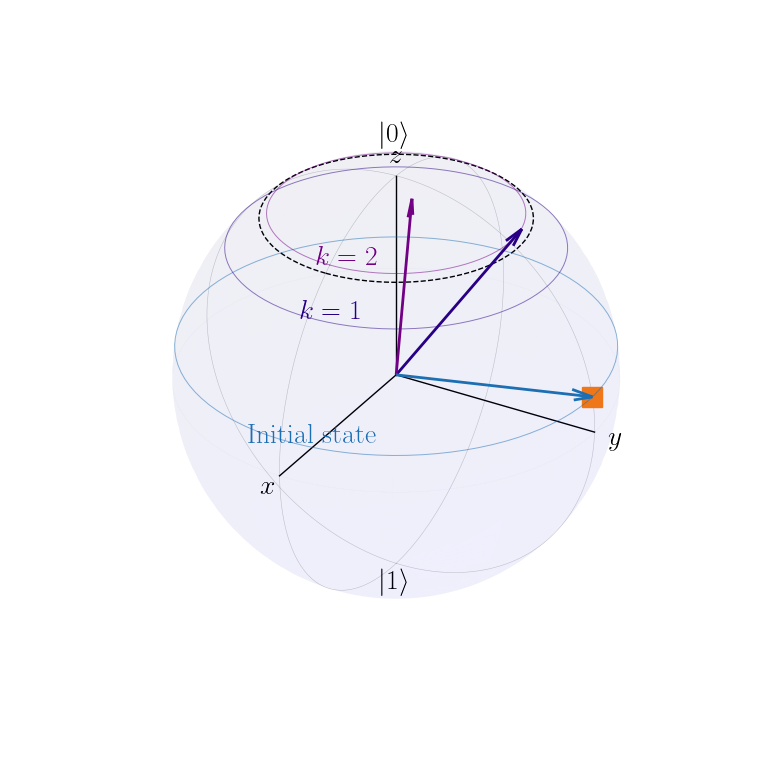

In [36]:
# Create the plot
ax = plot_bloch_sphere()

fidelity = 0.9
theta = 2 * np.arccos(np.sqrt(fidelity))
u = np.linspace(0, 2 * np.pi, 100)
x_latitude = np.outer(np.cos(u), np.sin(theta))
y_latitude = np.outer(np.sin(u), np.sin(theta))
z_latitude = np.outer(np.ones(np.size(u)), np.cos(theta))
ax.plot(x_latitude, y_latitude, z_latitude, color='k', lw=1, alpha=1,linestyle='--')


# Plot the Bloch sphere with vector
i=0
for state in states_mid:
    if i==0:
        ax = plot_bloch_vector(state,ax,color=color[i],text=texts[i],marker='s',marker_color='C1')
    else:
        ax = plot_bloch_vector(state,ax,color=color[i],text=texts[i])
    i+=1
# Show the plot
plt.savefig(f'plots/bloch_mid.pdf', bbox_inches="tight", pad_inches=-1.1)
plt.show()


### (c) The initial state is far from the ground state, with $F_{\text{initial}} = 10\%$. In this case, the target fidelity cannot be reached within $k=2$ steps and $M=2$.

0.0 0.8145759520503356 (-0.5800569095711983+0j)
-0.6390847655871552 0.668025005080452 (-0.10190766243710636-1.9902976434698883e-17j)
-0.654196162320383 0.22958975309952895 (0.42810588264165794-2.9080559971071337e-18j)


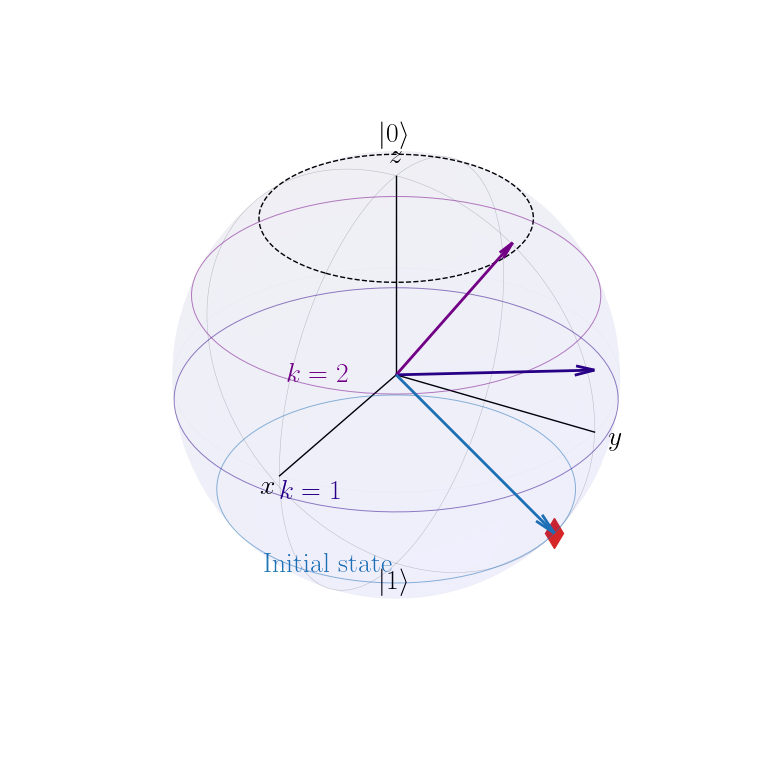

In [37]:
# Create the plot
ax = plot_bloch_sphere()

fidelity = 0.9
theta = 2 * np.arccos(np.sqrt(fidelity))
u = np.linspace(0, 2 * np.pi, 100)
x_latitude = np.outer(np.cos(u), np.sin(theta))
y_latitude = np.outer(np.sin(u), np.sin(theta))
z_latitude = np.outer(np.ones(np.size(u)), np.cos(theta))
ax.plot(x_latitude, y_latitude, z_latitude, color='k', lw=1, alpha=1,linestyle='--')

# Plot the Bloch sphere with vector
i=0
for state in states_bad:
    if i==0:
        ax = plot_bloch_vector(state,ax,color=color[i],text=texts[i],marker='d',marker_color='C3')
    else:
        ax = plot_bloch_vector(state,ax,color=color[i],text=texts[i])
    i+=1
# Show the plot
plt.savefig(f'plots/bloch_bad.pdf', bbox_inches="tight", pad_inches=-1.1)
plt.show()
